# Squeeze Flow of Thermal Interface Material (TIM) in 700 W AI GPU Packaging
### *From Reynolds Transport Theorem & Cauchy Momentum to Non-Newtonian Rheology and Chip Thermal Bottlenecks*

---

> **Pedagogical Design — Equations & Code Side-by-Side:**  
> Every derivation milestone in this notebook presents the **governing transport equations** **side-by-side** with the exact **Python implementation** in [`src/`](src/), followed immediately by an executable verification and visualization cell.

### Course Slide Decks Directly Synthesized in This Notebook
1. **Deck 1 — *Conservation and Transport Equations* :**
   * Finite Control Volumes (CV) vs. Material Systems , Influx/Efflux Sign Conventions , Leibniz Rule & Moving Boundaries , Gauss Divergence Theorem , 3D **Reynolds Transport Theorem (RTT)** , Incompressibility $\nabla\cdot\vec{u}=0$ , Fourier's Law of Heat Conduction $\vec{q}=-k\nabla T$ , and the 7-Point Verification Checklist .
2. **Deck 2 — *Momentum, Energy and Fluid Flow* :**
   * Cauchy Stress Tensor $\underline{\underline{\sigma}} = -p\underline{\underline{I}} + \underline{\underline{\tau}}$ & Traction $\vec{t}^{(\vec{n})} = \underline{\underline{\sigma}}\vec{n}$ , Rate-of-Deformation Tensor $\underline{\underline{D}} = \frac{1}{2}(\underline{\underline{G}}+\underline{\underline{G}}^T)$ & Simple Shear $\dot{\gamma}=\partial u_r/\partial z$ , Non-Newtonian Power-Law & Bingham Yield-Stress Fluids, Term-by-Term Navier–Stokes Reduction Reasons , Planar Slit / Poiseuille Flow , and Universal Conservation vs. Material-Specific Closure .
3. **Deck 3 — *Dimensionless Numbers as Ratios of Physical Effects* :**
   * Force & Stress Scales , Buckingham $\Pi$ Theorem , Dimensionless Navier–Stokes & Reynolds Number $Re = \text{inertia}/\text{viscosity}$ , Profile Collapse & Master Curves , and Biot/Fourier Thermal Resistance Ratios .


---
## 1. Physical System, Coordinate Frame & Benchmark Configuration (`src/params.py`)

A pea-sized droplet of thermal paste of constant volume $V_0 = 50\text{ mm}^3$ and initial height $h_0 = 1.0\text{ mm}$ is dispensed at the center of an **H100-class 700 W AI GPU die** ($A_{\text{die}} = 814\text{ mm}^2$). At $t = 0$, the heatsink/cold-plate assembly applies a constant clamping force $F_0 = 400\text{ N}$ downward along the $z$-axis.

<table>
<tr>
<th width="50%">Physical Quantities & Base Dimensions (<i>Dimensionless Numbers</i>, )</th>
<th width="50%">Python Implementation (<code>src/params.py</code>)</th>
</tr>
<tr>
<td valign="top">

**Equivalent-Disk Die Geometry & Heat Flux:**
$$R_{\text{die}} = \sqrt{\frac{A_{\text{die}}}{\pi}} = 16.10\text{ mm}, \qquad q'' = \frac{\dot{Q}}{A_{\text{die}}} = 86.0\text{ W/cm}^2$$

**Initial Droplet Radius ($t=0$):**
$$V_0 = \pi R_0^2 h_0 \implies R_0 = \sqrt{\frac{V_0}{\pi h_0}} = 3.99\text{ mm}$$

**Full-Coverage Transition Thickness ($R(t) = R_{\text{die}}$):**
$$h_c = \frac{V_0}{\pi R_{\text{die}}^2} = \frac{V_0}{A_{\text{die}}} = 61.43\,\mu\text{m}$$

**Three Candidate Constitutive Families ($[M, L, T]$ SI Units):**
* **Newtonian:** $\mu = 100\text{ Pa}\cdot\text{s}$ ($[\mu] = M L^{-1} T^{-1}$)
* **Power-Law:** $K = 100\text{ Pa}\cdot\text{s}^n$, $n \in \{0.5, 1.3\}$ ($[K] = M L^{-1} T^{n-2}$)
* **Bingham Plastic:** $\mu_p = 100\text{ Pa}\cdot\text{s}$, $\tau_y \in \{250, 5000\}\text{ Pa}$ ($[\tau_y] = M L^{-1} T^{-2}$)

</td>
<td valign="top">

```python
@dataclass(frozen=True)
class GPUSpec:
    name: str = "700 W AI GPU accelerator (H100-class)"
    A_die: float = 814e-6   # die area          [m^2]
    Q: float = 700.0        # heat load         [W]
    F0: float = 400.0       # clamping force    [N]

    @property
    def R_die(self) -> float:
        return math.sqrt(self.A_die / math.pi)

    @property
    def q_flux(self) -> float:
        return self.Q / self.A_die

@dataclass(frozen=True)
class DropletSpec:
    V0: float = 50e-9       # paste volume      [m^3]
    h0: float = 1.0e-3      # initial height    [m]

    @property
    def R0(self) -> float:
        return math.sqrt(self.V0 / (math.pi * self.h0))
```

</td>
</tr>
</table>


In [1]:
import sys
from pathlib import Path
import numpy as np

# Add src/ to path so we import the exact project modules
SRC_DIR = Path("src").resolve()
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

import params as prm
import rheology_models as rm
import thermal_coupling as tc
import diagnostics as dg

print(prm.describe())
hc_um = rm.cap_thickness(prm.DROPLET.V0, prm.GPU_700W.R_die) * 1e6
print(f"  Full-coverage transition thickness h_c = V0 / A_die = {hc_um:.2f} um")


700 W AI GPU accelerator (H100-class)
  A_die = 814 mm^2  ->  R_die = 16.10 mm
  Q = 700 W  ->  q'' = 86.0 W/cm^2
  F0 = 400 N
  V0 = 50 mm^3, h0 = 1.00 mm -> R0 = 3.99 mm
  k_TIM = 5.0 W/mK, k_air = 0.026 W/mK
  Full-coverage transition thickness h_c = V0 / A_die = 61.43 um


---
## 2. Milestone 1 — Reynolds Transport Theorem (RTT) & Deformable-CV Continuity

Following *Conservation and Transport Equations*, we first choose our control volume (CV) and its closed control surface (CS) $\partial V(t)$ before writing any force equation.

* **Deformable Cylindrical Pillbox CV:** Fix an arbitrary radial coordinate $r \le R(t)$ and let the CV span vertically from the stationary lower die surface $z = 0$ to the descending upper cold-plate surface $z = h(t)$.
* **Boundary Velocities $\vec{w}$:**
  1. Bottom face ($z = 0$, $\vec{n} = -\vec{e}_z$): stationary solid wall ($\vec{u} = \vec{w} = \vec{0}$) $\implies (\vec{u}-\vec{w})\cdot\vec{n} = 0$.
  2. Top face ($z = h(t)$, $\vec{n} = +\vec{e}_z$): impermeable moving plate ($\vec{u} = \vec{w} = \dot{h}\vec{e}_z$) $\implies (\vec{u}-\vec{w})\cdot\vec{n} = 0$ (zero mass crosses the top plate, **but** its downward motion $\dot{h} < 0$ shrinks $V(t) = \pi r^2 h(t)$).
  3. Lateral cylindrical face (radius $r$, $\vec{n} = +\vec{e}_r$): fixed radial coordinate ($\vec{w} = \vec{0}$), so $(\vec{u}-\vec{w})\cdot\vec{n} = u_r(r,z,t)$.

<table>
<tr>
<th width="52%">Step-by-Step Mathematical Derivation (<i>Conservation & Transport</i>, </th>
<th width="48%">Python Implementation (<code>src/rheology_models.py</code> & <code>src/diagnostics.py</code>)</th>
</tr>
<tr>
<td valign="top">

**Step 1 — Integral RTT for Total Mass ($C = \rho$, no mass generation):**
$$\frac{d}{dt}\int_{V(t)} \rho\,dV + \oint_{\partial V(t)} \rho(\vec{u}-\vec{w})\cdot\vec{n}\,dA = 0$$

**Step 2 — Incompressibility ($\rho = \text{const}$):**
$$\frac{d}{dt}\bigl[\pi r^2 h(t)\bigr] + \int_0^{h(t)} u_r(r,z,t)\,(2\pi r\,dz) = 0$$
$$\pi r^2 \dot{h} + 2\pi r \int_0^{h(t)} u_r(r,z,t)\,dz = 0$$

**Step 3 — Radial Volumetric Flux per Unit Circumference ($W \equiv -\dot{h} > 0$):**
$$\boxed{q_r(r,t) \equiv \int_0^{h(t)} u_r(r,z,t)\,dz = -\frac{r\dot{h}}{2} = \frac{rW}{2}} \quad [\text{m}^2/\text{s}]$$

**Step 4 — Differential Counterpart & Constant-Volume Wetted Radius:**
Integrating axisymmetric continuity $\frac{1}{r}\frac{\partial(ru_r)}{\partial r} + \frac{\partial u_z}{\partial z} = 0$ across $z \in [0,h]$ with $u_z(r,0)=0$ and $u_z(r,h)=\dot{h}$ gives the identical result $\frac{1}{r}\frac{\partial(rq_r)}{\partial r} = -\dot{h} = W$. Setting $r = R(t)$ where $dV_{\text{total}}/dt = 0$ yields the die-capped wetted radius:
$$\boxed{R(h) = \min\!\left(\sqrt{\frac{V_0}{\pi h}},\, R_{\text{die}}\right)}$$

</td>
<td valign="top">

```python
# src/rheology_models.py
def wetted_radius(h, V0: float, R_die: Optional[float] = None):
    # R(h) = min( sqrt(V0/(pi h)), R_die )
    R = np.sqrt(V0 / (np.pi * np.asarray(h, dtype=float)))
    return R if R_die is None else np.minimum(R, R_die)

def cap_thickness(V0: float, R_die: Optional[float]) -> float:
    # Thickness h_c = V0/(pi R_die^2) where dot reaches die edge
    return 0.0 if R_die is None else V0 / (np.pi * R_die**2)

# src/diagnostics.py -- Numerical verification of RTT flux
# across all 3 constitutive velocity profiles u_r(r, z):
#   q_num(r) = \int_0^h u_r(r, z) dz  ==  r * W / 2
for a, b in zip(z[:-1], z[1:]):
    zz = 0.5 * (b - a) * zg[0] + 0.5 * (a + b)
    q += 0.5 * (b - a) * (
        rm.velocity(r[:, None], zz[None, :], h, W, f) @ zg[1]
    )
err = max(err, _rel(q, r * W / 2))
```

</td>
</tr>
</table>


In [2]:
# Live Verification of Milestone 1: RTT radial flux q_r(r) = int_0^h u_r(r,z) dz == r W / 2
h_test = 80e-6  # 80 um gap (in constant-volume spreading phase, h > h_c = 61.43 um)
R_test = float(rm.wetted_radius(h_test, prm.DROPLET.V0, prm.GPU_700W.R_die))
r_pts = np.linspace(0.1, 1.0, 5) * R_test
z_quad, w_quad = np.polynomial.legendre.leggauss(64)
z_pts = 0.5 * h_test * (z_quad + 1.0)

print(f"Testing RTT kinematic identity at h = {h_test*1e6:.1f} um, R(h) = {R_test*1e3:.2f} mm:")
for fluid in [prm.NEWTONIAN, prm.SHEAR_THINNING, prm.SHEAR_THICKENING, prm.BINGHAM]:
    W_val = float(np.atleast_1d(rm.squeeze_rate(h_test, fluid, prm.GPU_700W.F0, prm.DROPLET.V0, prm.GPU_700W.R_die))[0])
    u_grid = rm.velocity(r_pts[:, None], z_pts[None, :], h_test, W_val, fluid)
    q_integral = 0.5 * h_test * (u_grid @ w_quad)
    q_rtt = 0.5 * r_pts * W_val
    max_rel_err = float(np.max(np.abs(q_integral - q_rtt) / q_rtt))
    print(f"  {fluid.label:28s} | W = {W_val*1e6:8.3f} um/s | max |int u_r dz - rW/2| / (rW/2) = {max_rel_err:.2e}")


Testing RTT kinematic identity at h = 80.0 um, R(h) = 14.10 mm:
  Newtonian                    | W =   10.981 um/s | max |int u_r dz - rW/2| / (rW/2) = 1.71e-15
  Shear-thinning (n=0.5)       | W =  457.763 um/s | max |int u_r dz - rW/2| / (rW/2) = 5.48e-08
  Shear-thickening (n=1.3)     | W =    4.678 um/s | max |int u_r dz - rW/2| / (rW/2) = 2.30e-06
  Bingham ($\tau_y$=250 Pa)    | W =   10.225 um/s | max |int u_r dz - rW/2| / (rW/2) = 2.98e-06


---
## 3. Milestone 2 — Cauchy Momentum Equation, Lubrication Reduction & Universal Shear-Stress Distribution

From *Momentum, Energy and Fluid Flow* , the local momentum balance **before choosing any rheological law** is the Cauchy momentum equation with stress split into isotropic pressure $-p\underline{\underline{I}}$ and deviatoric extra stress $\underline{\underline{\tau}}$:
$$\rho\frac{D\vec{u}}{Dt} = \nabla\cdot\underline{\underline{\sigma}} + \rho\vec{b} = -\nabla p + \nabla\cdot\underline{\underline{\tau}} + \rho\vec{b}$$

In axisymmetric cylindrical coordinates $(r,\theta,z)$ with $u_\theta = 0$ and $\partial/\partial\theta = 0$, the radial component is:
$$\rho\left(\frac{\partial u_r}{\partial t} + u_r\frac{\partial u_r}{\partial r} + u_z\frac{\partial u_r}{\partial z}\right) = -\frac{\partial p}{\partial r} + \frac{1}{r}\frac{\partial(r\tau_{rr})}{\partial r} - \frac{\tau_{\theta\theta}}{r} + \frac{\partial \tau_{rz}}{\partial z}$$

<table>
<tr>
<th width="52%">Order-of-Magnitude Scaling & Reduction (<i>Momentum</i>, ; <i>Dimensionless</i>, )</th>
<th width="48%">Python Implementation (<code>src/rheology_models.py</code> & <code>src/diagnostics.py</code>)</th>
</tr>
<tr>
<td valign="top">

**Step 1 — Characteristic Scales:**
$$r \sim R, \quad z \sim h, \quad u_z \sim W = -\dot{h}, \quad u_r \sim U_r = \frac{RW}{h}, \quad \epsilon \equiv \frac{h}{R} \ll 1$$

**Step 2 — Strain-Rate & Deviatoric Stress Comparison:**
$$\dot{\gamma}_{rz} = \frac{\partial u_r}{\partial z} + \frac{\partial u_z}{\partial r} \sim \frac{U_r}{h}\bigl(1 + \mathcal{O}(\epsilon^2)\bigr) \implies \frac{|\partial\tau_{rz}/\partial z|}{|\frac{1}{r}\partial(r\tau_{rr})/\partial r|} \sim \frac{1}{\epsilon^2} \gg 1$$
For our 700 W GPU ($h \sim 50\,\mu\text{m}$, $R \sim 16\text{ mm}$), $\epsilon \approx 3\times 10^{-3} \implies \epsilon^2 \approx 10^{-5}$. All normal-stress gradients and $\partial u_z/\partial r$ vanish by $\mathcal{O}(\epsilon^2)$.

**Step 3 — Squeeze Reynolds Number (Inertial vs. Viscous Force Scale):**
$$\frac{|\rho u_r \partial u_r/\partial r|}{|\partial\tau_{rz}/\partial z|} \sim \frac{\rho U_r^2 / R}{\mu_{\text{eff}} U_r / h^2} = \frac{\rho W h}{\mu_{\text{eff}}} \equiv Re_{\text{sq}} \ll 1$$
At $W \sim 10^{-4}\text{ m/s}$, $\mu \sim 100\text{ Pa}\cdot\text{s}$, $Re_{\text{sq}} \sim 10^{-10} \ll 1$ (creeping flow).

**Step 4 — Reduced Lubrication Equations & Universal Linear Shear Stress:**
$$\frac{\partial p}{\partial z} = 0 \implies p = p(r,t), \qquad 0 = -\frac{\partial p}{\partial r} + \frac{\partial\tau_{rz}}{\partial z}$$
Defining $G(r,t) \equiv -\frac{\partial p}{\partial r} > 0$ and midplane coordinate $\zeta \equiv z - \frac{h}{2} \in [-\frac{h}{2}, +\frac{h}{2}]$, symmetry $u_r(r,z)=u_r(r,h-z)$ requires $\tau_{rz}(r,h/2)=0$, giving for **every** fluid model:
$$\boxed{\tau_{rz}(r,z) = -G(r)\left(z - \frac{h}{2}\right) = -G(r)\,\zeta}$$

</td>
<td valign="top">

```python
# src/diagnostics.py -- Dimensionless assumption trackers
def aspect_ratio(h, R):
    # eps = h / R  (lubrication requires eps << 1)
    return np.asarray(h, float) / np.asarray(R, float)

def characteristic_shear_rate(h, R, W):
    # gamma_c = R W / h^2
    return (np.asarray(R, float) * np.asarray(W, float)
            / np.asarray(h, float) ** 2)

def squeeze_reynolds(fluid: Fluid, h, R, W):
    # Re_sq = rho W h / mu_eff  (creeping flow: Re_sq << 1)
    return (fluid.rho * np.asarray(W, float)
            * np.asarray(h, float)
            / effective_viscosity(fluid, h, R, W))

# src/rheology_models.py -- Universal shear stress profile
def shear_stress(r, z, h: float, W: float, fluid: Fluid):
    # tau_rz(r, z) = -G(r) (z - h/2) -- linear for EVERY fluid
    r, z = np.broadcast_arrays(
        np.asarray(r, float), np.asarray(z, float)
    )
    return -pressure_gradient(r, h, W, fluid) * (z - 0.5 * h)
```

</td>
</tr>
</table>


---
## 4. Milestone 3 — Newtonian Squeeze Flow: Stefan's Law & Constant-Volume Two-Phase Analytical Solution

For an incompressible Newtonian fluid (*Momentum, Energy and Fluid Flow*), the constitutive closure in simple shear is $\tau_{rz} = \mu\frac{\partial u_r}{\partial z}$. Because $u_r$ peaks at the midplane $\zeta = 0$ and vanishes at the walls $\zeta = \pm H$ ($H \equiv h/2$), $\frac{\partial u_r}{\partial z}$ has the opposite sign of $\zeta$.

<table>
<tr>
<th width="52%">Step-by-Step Mathematical Derivation (Stefan Solution)</th>
<th width="48%">Python Implementation (<code>src/rheology_models.py</code>)</th>
</tr>
<tr>
<td valign="top">

**Step 1 — Parabolic Radial Velocity Profile ($H \equiv h/2$, $\zeta = z - H$):**
$$\mu\frac{\partial u_r}{\partial \zeta} = -G(r)\zeta \xrightarrow{u_r(\pm H)=0} \boxed{u_r(r,z) = \frac{G(r)}{2\mu}\left(H^2 - \zeta^2\right) = \frac{G(r)}{2\mu}z(h-z)}$$

**Step 2 — Match Flux to RTT Continuity ($q_r = rW/2$):**
$$q_r = 2\int_0^H \frac{G}{2\mu}(H^2 - \zeta^2)\,d\zeta = \frac{2GH^3}{3\mu} = \frac{Gh^3}{12\mu} = \frac{rW}{2} \implies \boxed{G(r) = -\frac{\partial p}{\partial r} = \frac{6\mu W r}{h^3}}$$

**Step 3 — Parabolic Pressure Distribution ($p(R) = p_\infty$):**
$$p(r) - p_\infty = \int_r^R \frac{6\mu W r'}{h^3}\,dr' = \boxed{\frac{3\mu W}{h^3}\left(R^2 - r^2\right)}$$

**Step 4 — Normal Clamping Force $F$ (Stefan's Equation):**
$$F = \int_0^R \bigl(p(r)-p_\infty\bigr)2\pi r\,dr = \boxed{\frac{3\pi\mu W R^4}{2h^3}}$$

**Step 5 — Two-Phase Constant-Force Trajectory ($F = F_0$, $W = -dh/dt$):**
* **Phase 1 (Constant-Volume Spreading, $R^2 = V_0/(\pi h) < R_{\text{die}}^2$, $h > h_c$):**
  $$F_0 = \frac{3\mu V_0^2}{2\pi h^5}\left(-\frac{dh}{dt}\right) \implies \boxed{h(t) = h_0\left(1 + \frac{8\pi F_0 h_0^4}{3\mu V_0^2}\,t\right)^{-1/4}} \;\; (h \propto t^{-1/4})$$
* **Phase 2 (Die-Capped Constant-Area Squeeze, $R = R_{\text{die}}$, $t \ge t_c$):**
  $$F_0 = \frac{3\pi\mu R_{\text{die}}^4}{2h^3}\left(-\frac{dh}{dt}\right) \implies \boxed{h(t) = \left[h_c^{-2} + \frac{4F_0(t - t_c)}{3\pi\mu R_{\text{die}}^4}\right]^{-1/2}} \;\; (h \propto t^{-1/2})$$

</td>
<td valign="top">

```python
# src/rheology_models.py -- Newtonian (Stefan 1874)
def newtonian_force(h, R, W, mu: float):
    # F = 3 pi mu W R^4 / (2 h^3),  W = -dh/dt
    return 3.0 * np.pi * mu * W * R**4 / (2.0 * h**3)

def newtonian_rate(h, F0: float, mu: float, V0: float, R_die=None):
    # Squeeze rate W(h) = -dh/dt from F = F0
    h = np.asarray(h, dtype=float)
    R = wetted_radius(h, V0, R_die)
    return 2.0 * F0 * h**3 / (3.0 * np.pi * mu * R**4)

def newtonian_h(t, F0: float, mu: float, V0: float,
                h0: float, R_die=None):
    # Closed-form h(t): Phase 1 (V0 const) -> Phase 2 (R=R_die)
    t = np.asarray(t, dtype=float)
    h1 = h0 * (
        1.0 + 8.0 * np.pi * F0 * h0**4 * t / (3.0 * mu * V0**2)
    ) ** -0.25
    hc = cap_thickness(V0, R_die)
    if R_die is None:
        return h1
    tc = (((h0 / hc) ** 4 - 1.0)
          * 3.0 * mu * V0**2 / (8.0 * np.pi * F0 * h0**4))
    h2 = (
        hc**-2 + 4.0 * F0 * np.maximum(t - tc, 0.0)
        / (3.0 * np.pi * mu * R_die**4)
    ) ** -0.5
    return np.where(t < tc, h1, h2)
```

</td>
</tr>
</table>


---
## 5. Milestone 4 — Ostwald–de Waele Power-Law Squeeze Flow: Scott's Equation & Scaling Exponents

Real particle-filled thermal pastes are strongly **shear-thinning** ($n < 1$): as the gap $h$ shrinks, the wall shear rate $\dot{\gamma}_w \sim RW/h^2$ climbs rapidly, dropping the apparent viscosity $\mu_{\text{app}} = K|\dot{\gamma}|^{n-1}$ (*Momentum, Energy and Fluid Flow*, Slide 95).

<table>
<tr>
<th width="52%">Step-by-Step Mathematical Derivation (Scott Solution)</th>
<th width="48%">Python Implementation (<code>src/rheology_models.py</code>)</th>
</tr>
<tr>
<td valign="top">

**Step 1 — Power-Law Constitutive Closure & Velocity Profile ($\zeta \ge 0$):**
$$\tau_{rz} = K\left|\frac{\partial u_r}{\partial z}\right|^{n-1}\frac{\partial u_r}{\partial z} = -G\zeta \implies -\frac{\partial u_r}{\partial \zeta} = \left(\frac{G}{K}\right)^{1/n}\zeta^{1/n}$$
Integrating with no-slip $u_r(\pm H) = 0$ ($H = h/2$):
$$\boxed{u_r(r,z) = \frac{n}{n+1}\left(\frac{G(r)}{K}\right)^{1/n}\left(H^{\frac{n+1}{n}} - |\zeta|^{\frac{n+1}{n}}\right)}$$

**Step 2 — Radial Flux & Pressure Gradient $G(r)$:**
$$q_r = 2\int_0^H u_r\,d\zeta = \frac{2n}{2n+1}\left(\frac{G}{K}\right)^{1/n} H^{\frac{2n+1}{n}} = \frac{rW}{2}$$
$$\implies \boxed{G(r) = -\frac{\partial p}{\partial r} = \frac{2K}{h^{2n+1}}\left(\frac{2n+1}{n}\right)^n W^n r^n}$$

**Step 3 — Radial Pressure Profile & Clamping Force (Scott's Equation):**
$$p(r) - p_\infty = \frac{2K}{(n+1)h^{2n+1}}\left(\frac{2n+1}{n}\right)^n W^n\left(R^{n+1} - r^{n+1}\right)$$
$$F = \int_0^R \bigl(p(r)-p_\infty\bigr)2\pi r\,dr = \boxed{\frac{2\pi K}{n+3}\left(\frac{2n+1}{n}\right)^n \frac{W^n R^{n+3}}{h^{2n+1}}}$$

**Step 4 — Constant-Volume ODE ($R = \sqrt{V_0/(\pi h)}$) & Time-Scaling Exponent:**
$$F_0 = \frac{2\pi K}{n+3}\left(\frac{2n+1}{n}\right)^n \left(\frac{V_0}{\pi}\right)^{\frac{n+3}{2}}\frac{(-\dot{h})^n}{h^{\frac{5n+5}{2}}} \implies -\frac{dh}{dt} = A\,h^m, \;\; m = \frac{5n+5}{2n}$$
Integrating yields the analytical trajectory and late-time power-law exponent:
$$\boxed{h(t) = \bigl[h_0^{1-m} + (m-1)At\bigr]^{\frac{1}{1-m}} \propto t^{-\frac{2n}{3n+5}}}$$
*(Check $n=1$: $m = 5$, $\frac{1}{1-m} = -\frac{1}{4}$, recovering Stefan's Newtonian law identically!)*

</td>
<td valign="top">

```python
# src/rheology_models.py -- Power-Law (Scott 1931)
def _pl_coeff(n: float) -> float:
    return ((2.0 * n + 1.0) / n) ** n

def power_law_force(h, R, W, K: float, n: float):
    # F = 2 pi K/(n+3) ((2n+1)/n)^n W^n R^{n+3} / h^{2n+1}
    return (2.0 * np.pi * K / (n + 3.0) * _pl_coeff(n)
            * W**n * R ** (n + 3.0) / h ** (2.0 * n + 1.0))

def power_law_h(t, fluid: PowerLaw, F0: float, V0: float,
                h0: float, R_die=None):
    # Closed-form h(t): Phase 1 (m=(5n+5)/(2n)) -> Phase 2 (k=(2n+1)/n)
    K, n = fluid.K, fluid.n
    t = np.asarray(t, dtype=float)
    c = _pl_coeff(n)
    m = (5.0 * n + 5.0) / (2.0 * n)
    A = ((F0 * (n + 3.0) / (2.0 * np.pi * K * c)) ** (1.0 / n)
         * (np.pi / V0) ** ((n + 3.0) / (2.0 * n)))
    hc = cap_thickness(V0, R_die)
    tc = ((hc ** (1.0 - m) - h0 ** (1.0 - m))
          / ((m - 1.0) * A)) if hc > 0 else np.inf
    h1 = (h0 ** (1.0 - m) + (m - 1.0) * A * t) ** (1.0 / (1.0 - m))
    if R_die is None or not np.isfinite(tc):
        return h1
    k = (2.0 * n + 1.0) / n
    B = (F0 * (n + 3.0) / (2.0 * np.pi * K * c * R_die ** (n + 3.0))) ** (1.0 / n)
    h2 = (hc ** (1.0 - k) + (k - 1.0) * B * np.maximum(t - tc, 0.0)) ** (1.0 / (1.0 - k))
    return np.where(t < tc, h1, h2)
```

</td>
</tr>
</table>


---
## 6. Milestone 5 — Bingham Yield-Stress Squeeze Flow: Covey–Stanmore Cubic, Pseudo-Plug Paradox & Plastic Stall ($h^*, R^*$)

Heavily loaded silver/alumina thermal pastes form a percolated particle network with a finite **yield stress** $\tau_y$ (*Momentum, Energy and Fluid Flow*, Slide 96):
$$|\tau_{rz}| > \tau_y \implies \tau_{rz} = \tau_y\,\text{sgn}(\dot{\gamma}) + \mu_p\dot{\gamma}, \qquad |\tau_{rz}| \le \tau_y \implies \dot{\gamma} = 0$$

Because $\tau_{rz}(r,z) = -G(r)\zeta$ vanishes at the midplane $\zeta = 0$, there is **always** a core $|\zeta| \le z_0(r)$ where $|\tau_{rz}| \le \tau_y$:
$$\boxed{z_0(r) = \frac{\tau_y}{G(r)}, \qquad \xi_0(r) \equiv \frac{2z_0(r)}{h} = \frac{2\tau_y}{h\,G(r)} \in (0, 1]}$$

<table>
<tr>
<th width="52%">Step-by-Step Mathematical Derivation (Covey–Stanmore & Stall Limit)</th>
<th width="48%">Python Implementation (<code>src/rheology_models.py</code>)</th>
</tr>
<tr>
<td valign="top">

**Step 1 — Piecewise Velocity Profile ($H = h/2$, $z_0 = \tau_y/G$):**
In the yielded wall layer $\zeta \in [z_0, H]$, $-\mu_p\frac{\partial u_r}{\partial\zeta} = G\zeta - \tau_y = G(\zeta - z_0)$:
$$\boxed{u_r(r,z) = \begin{cases} \dfrac{G}{2\mu_p}(H^2 - \zeta^2) - \dfrac{\tau_y}{\mu_p}(H - \zeta), & z_0 \le |\zeta| \le H \\[6pt] u_{\text{plug}}(r) = \dfrac{G}{2\mu_p}(H - z_0)^2, & 0 \le |\zeta| < z_0 \end{cases}}$$

**Step 2 — Buckingham–Reiner Flux & Normalised Cubic for $\xi_0(r)$:**
$$q_r = 2\int_0^H u_r\,d\zeta = \frac{Gh^3}{12\mu_p}\left(1 - \frac{3}{2}\xi_0 + \frac{1}{2}\xi_0^3\right) = \frac{rW}{2}$$
Substituting $G = 2\tau_y/(h\xi_0)$ and defining dimensionless radial shear $S(r) \equiv \frac{3\mu_p r W}{\tau_y h^2}$:
$$\boxed{\xi_0^3 - \bigl(3 + 2S(r)\bigr)\xi_0 + 2 = 0} \implies \xi_0(S) = \frac{2}{\sqrt{a}}\sin\!\left(\frac{1}{3}\arcsin(a^{3/2})\right)$$
where $a = \frac{3}{3+2S}$. At the edge $r=R$, $S(R) = \Lambda \equiv \frac{3\mu_p R W}{\tau_y h^2} = \frac{3}{Bn}$.

**Step 3 — Dimensionless Force Function $\Phi(\Lambda)$ & Plastic Stall ($W \to 0$):**
Integration by parts gives $F = \pi\int_0^R r^2 G(r)\,dr = \frac{2\pi\tau_y R^3}{3h}\Phi(\Lambda)$, where:
$$\boxed{\Phi(\Lambda) = 3\int_0^1 \frac{s^2}{\xi_0(\Lambda s)}\,ds}, \qquad \Phi(0) = 1, \quad \Phi(\Lambda \gg 1) \sim \frac{3}{4}\Lambda + \frac{3}{2}$$
As $W \to 0$ ($\Lambda \to 0$, $\xi_0 \to 1$, $G \to 2\tau_y/h$), $\Phi(0)=1$, so squeezing **permanently stalls** at a finite thickness $h^* > 0$:
$$F_0 = \frac{2\pi\tau_y (R^*)^3}{3h^*} \implies \boxed{h_{\text{vol}}^* = \left(\frac{2\tau_y V_0^{3/2}}{3\sqrt{\pi}F_0}\right)^{2/5}, \quad h_{\text{area}}^* = \frac{2\pi\tau_y R_{\text{die}}^3}{3F_0}}$$
Setting $h_{\text{vol}}^* = h_c = V_0/(\pi R_{\text{die}}^2)$ gives the exact critical yield stress $\tau_{y,\text{crit}} = \frac{3F_0 h_c}{2\pi R_{\text{die}}^3} = \frac{3F_0 V_0}{2\pi^2 R_{\text{die}}^5} = 2812.8\text{ Pa}$ ($\approx 2.81\text{ kPa}$).

> **The Bingham Squeeze-Flow Paradox (Lipscomb & Denn 1984):** Since $u_{\text{plug}}(r)$ increases with $r$, $\frac{\partial u_r}{\partial r} \ne 0$ inside the core, so the full 2D strain-rate invariant $\dot{\gamma}_{\text{II}} = \mathcal{O}(\epsilon)$ is non-zero. Thus $|\zeta| \le z_0(r)$ is a weakly-deforming **pseudo-plug** rather than a strictly rigid body, while the plastic stall limit $h^*$ remains **exact**.

</td>
<td valign="top">

```python
# src/rheology_models.py -- Cancellation-free Viete cubic root
def bingham_plug_fraction(S):
    # Exact root xi0(S) in (0, 1] of xi^3 - (3+2S) xi + 2 = 0
    S = np.maximum(np.asarray(S, dtype=float), 0.0)
    a = 3.0 / (3.0 + 2.0 * S)
    one_minus_y = -np.expm1(1.5 * np.log1p(-2.0 * S / (3.0 + 2.0 * S)))
    y = a**1.5
    asin_y = np.where(
        y > 0.5,
        0.5 * np.pi - 2.0 * np.arcsin(
            np.sqrt(np.clip(0.5 * one_minus_y, 0.0, 1.0))
        ),
        np.arcsin(np.minimum(y, 1.0)),
    )
    return 2.0 / np.sqrt(a) * np.sin(asin_y / 3.0)

def bingham_stall(F0: float, tau_y: float, V0: float, R_die=None):
    # Plastic-limit stall thickness h* and spread radius R*
    h_vol = (2.0 * tau_y * V0**1.5 / (3.0 * np.sqrt(np.pi) * F0)) ** 0.4
    R_vol = np.sqrt(V0 / (np.pi * h_vol))
    if R_die is None or R_vol < R_die:
        return h_vol, R_vol, False
    return 2.0 * np.pi * tau_y * R_die**3 / (3.0 * F0), R_die, True
```

</td>
</tr>
</table>


In [3]:
# Live Comparison of Local Profiles (Fig 1 & Fig 2) & Bingham Plastic Stall Regimes (Fig 4)
from IPython.display import Image, display

tau_crit = float(rm.bingham_critical_yield_stress(prm.GPU_700W.F0, prm.DROPLET.V0, prm.GPU_700W.R_die))
for tau_val in [250.0, tau_crit, 5000.0]:
    h_st, R_st, cov = rm.bingham_stall(prm.GPU_700W.F0, tau_val, prm.DROPLET.V0, prm.GPU_700W.R_die)
    cov_pct = (min(R_st, prm.GPU_700W.R_die) / prm.GPU_700W.R_die) ** 2 * 100.0
    print(f"tau_y = {tau_val:6.1f} Pa -> h* = {h_st*1e6:6.2f} um | R* = {R_st*1e3:5.2f} mm | Die Coverage = {cov_pct:5.1f}% | Full Coverage: {cov}")

display(Image(filename="figures/fig1_velocity_stress.png", width=880))
display(Image(filename="figures/fig2_pressure_coverage.png", width=880))
display(Image(filename="figures/fig4_bingham_plug_map.png", width=880))


tau_y =  250.0 Pa -> h* =   5.46 um | R* = 16.10 mm | Die Coverage = 100.0% | Full Coverage: True
tau_y = 2812.8 Pa -> h* =  61.43 um | R* = 16.10 mm | Die Coverage = 100.0% | Full Coverage: True
tau_y = 5000.0 Pa -> h* =  77.32 um | R* = 14.35 mm | Die Coverage =  79.4% | Full Coverage: False
<IPython.core.display.Image object>
<IPython.core.display.Image object>
<IPython.core.display.Image object>


---
## 7. Milestone 6 — Energy Transport: 1D Fourier Conduction & Parallel Air-Gap Thermal Resistance Network

From *Conservation and Transport Equations*  and *Dimensionless Numbers* , steady 1D heat conduction across a planar bondline of thickness $h$ without internal generation obeys Fourier's law:
$$q_z'' = -k\frac{dT}{dz} = \text{const} \implies \Delta T = \frac{q_z''\,h}{k}, \qquad R_{\text{th}} = \frac{\Delta T}{\dot{Q}} = \frac{h}{k\,A}$$

When a high-yield-stress Bingham paste stalls at $R^* < R_{\text{die}}$, the wetted central circle $A_{\text{cov}} = \pi (R^*)^2$ conducts through TIM ($k_{\text{TIM}} = 5.0\text{ W/(m}\cdot\text{K)}$), while the unwetted outer annulus $A_{\text{unc}} = A_{\text{die}} - A_{\text{cov}}$ traps stagnant air ($k_{\text{air}} = 0.026\text{ W/(m}\cdot\text{K)}$ — nearly **200× lower** conductivity!).

<table>
<tr>
<th width="52%">Step-by-Step Mathematical Derivation (Parallel Thermal Network)</th>
<th width="48%">Python Implementation (<code>src/thermal_coupling.py</code>)</th>
</tr>
<tr>
<td valign="top">

**Step 1 — Wetted & Unwetted Die Areas:**
$$A_{\text{cov}}(t) = \pi\bigl[\min(R(t), R_{\text{die}})\bigr]^2, \qquad A_{\text{unc}}(t) = A_{\text{die}} - A_{\text{cov}}(t)$$

**Step 2 — Parallel Conduction Conductances Across Gap $h(t)$:**
$$\frac{1}{R_{\text{TIM,eff}}(t)} = \frac{1}{R_{\text{cov}}} + \frac{1}{R_{\text{air}}} = \frac{k_{\text{TIM}}A_{\text{cov}}(t) + k_{\text{air}}A_{\text{unc}}(t)}{h(t)}$$
$$\implies \boxed{R_{\text{TIM,eff}}(t) = \frac{h(t)}{k_{\text{TIM}}A_{\text{cov}}(t) + k_{\text{air}}\bigl(A_{\text{die}} - A_{\text{cov}}(t)\bigr)}}$$

**Step 3 — Die-Average TIM Temperature Rise & Local Perimeter Hotspot:**
$$\boxed{\Delta T_{\text{TIM}}(t) = \dot{Q}\,R_{\text{TIM,eff}}(t)}, \qquad \boxed{\Delta T_{\text{hotspot}}(t) = \frac{q''\,h(t)}{k_{\text{air}}}} \;\; (\text{if } R < R_{\text{die}})$$
Notice the double penalty of a high-yield-stress stall ($R^* < R_{\text{die}}$):
1. $h^*$ stays large (linear numerator penalty in $R_{\text{TIM,eff}}$), **and**
2. $A_{\text{cov}} < A_{\text{die}}$ shrinks the denominator (inverse coverage penalty), while the uncovered die perimeter sees $k_{\text{air}} \ll k_{\text{TIM}}$.

</td>
<td valign="top">

```python
# src/thermal_coupling.py -- Component 3: Energy transport
def covered_area(R, gpu: GPUSpec = GPU_700W):
    # Wetted die area A_cov = pi min(R, R_die)^2 [m^2]
    return np.pi * np.minimum(np.asarray(R, float), gpu.R_die) ** 2

def tim_resistance(h, R, gpu: GPUSpec = GPU_700W,
                   th: ThermalSpec = THERMAL):
    # Effective bondline resistance of parallel TIM/air network [K/W]
    h = np.asarray(h, float)
    A_cov = covered_area(R, gpu)
    A_unc = np.maximum(gpu.A_die - A_cov, 0.0)
    return h / (th.k_tim * A_cov + th.k_air * A_unc)

def delta_T_tim(h, R, gpu: GPUSpec = GPU_700W,
                th: ThermalSpec = THERMAL):
    # Die-average temperature rise across the TIM, Q * R_TIM,eff [K]
    return gpu.Q * tim_resistance(h, R, gpu, th)
```

</td>
</tr>
</table>


Rheological Model                  | h(60s) [um] | R(60s) [mm] | Coverage [%] | R_TIM [K/W] | dT_TIM [K] | dT_hot [K]
---------------------------------------------------------------------------------------------------------------------
Shear-Thinning (n=0.5, K=100)      |       10.77 |       16.10 |        100.0 |     0.00265 |       1.85 |        0.0
Newtonian (mu=100 Pa.s)            |       24.62 |       16.10 |        100.0 |     0.00605 |       4.23 |        0.0
Shear-Thickening (n=1.3, K=100)    |       33.04 |       16.10 |        100.0 |     0.00812 |       5.68 |        0.0
Bingham Nominal (tau_y=250 Pa)     |       27.45 |       16.10 |        100.0 |     0.00675 |       4.72 |        0.0
Bingham High-Yield (tau_y=5 kPa)   |       78.39 |       14.25 |         78.4 |     0.02454 |      17.18 |     2592.6


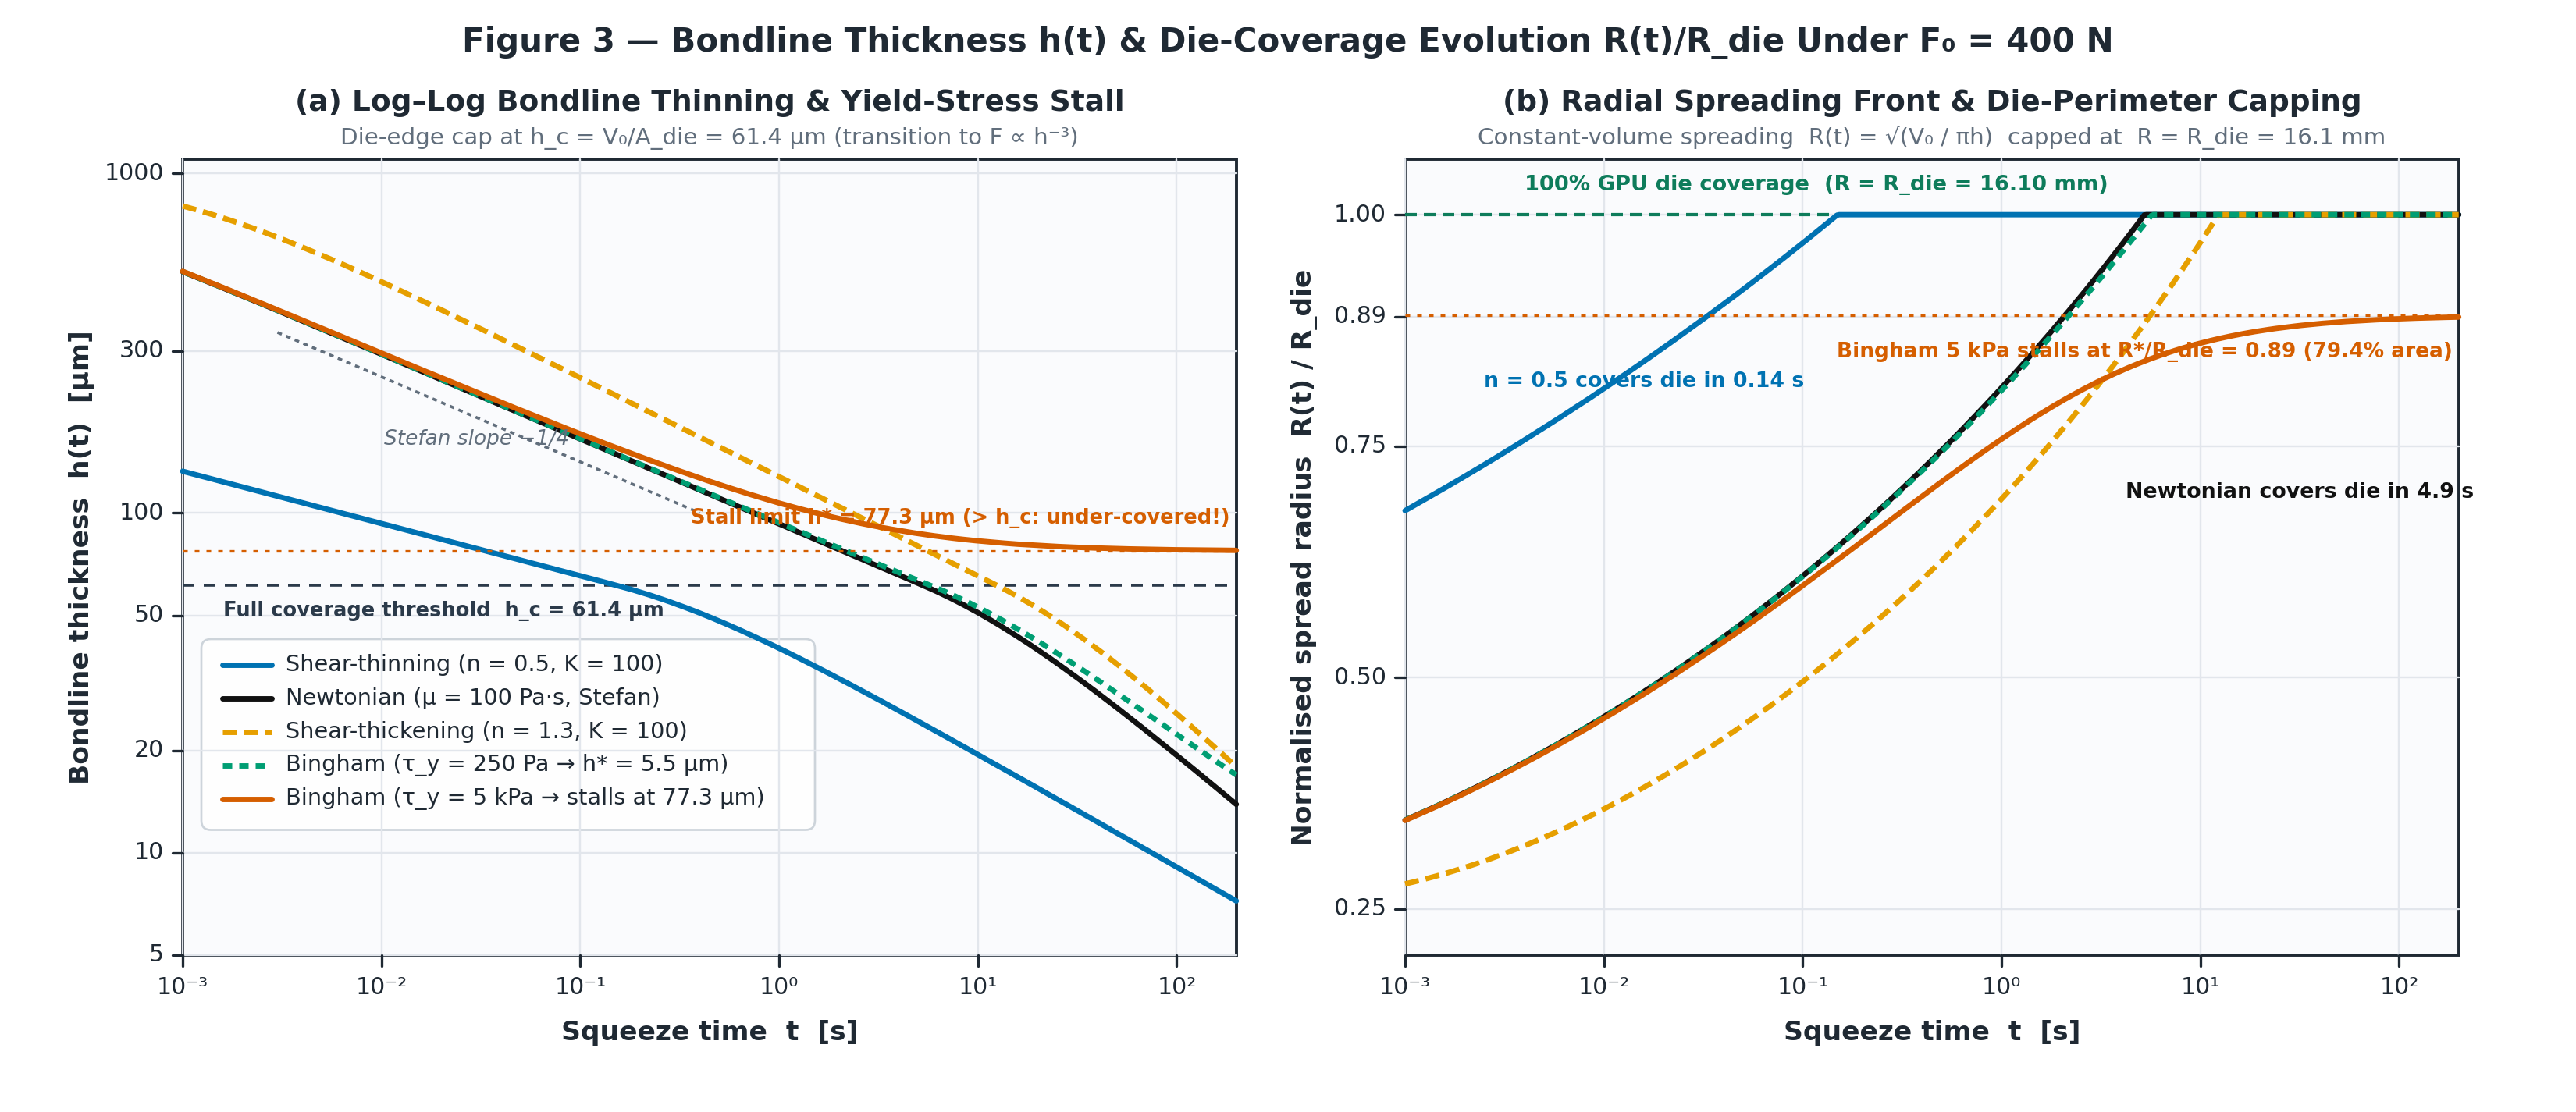

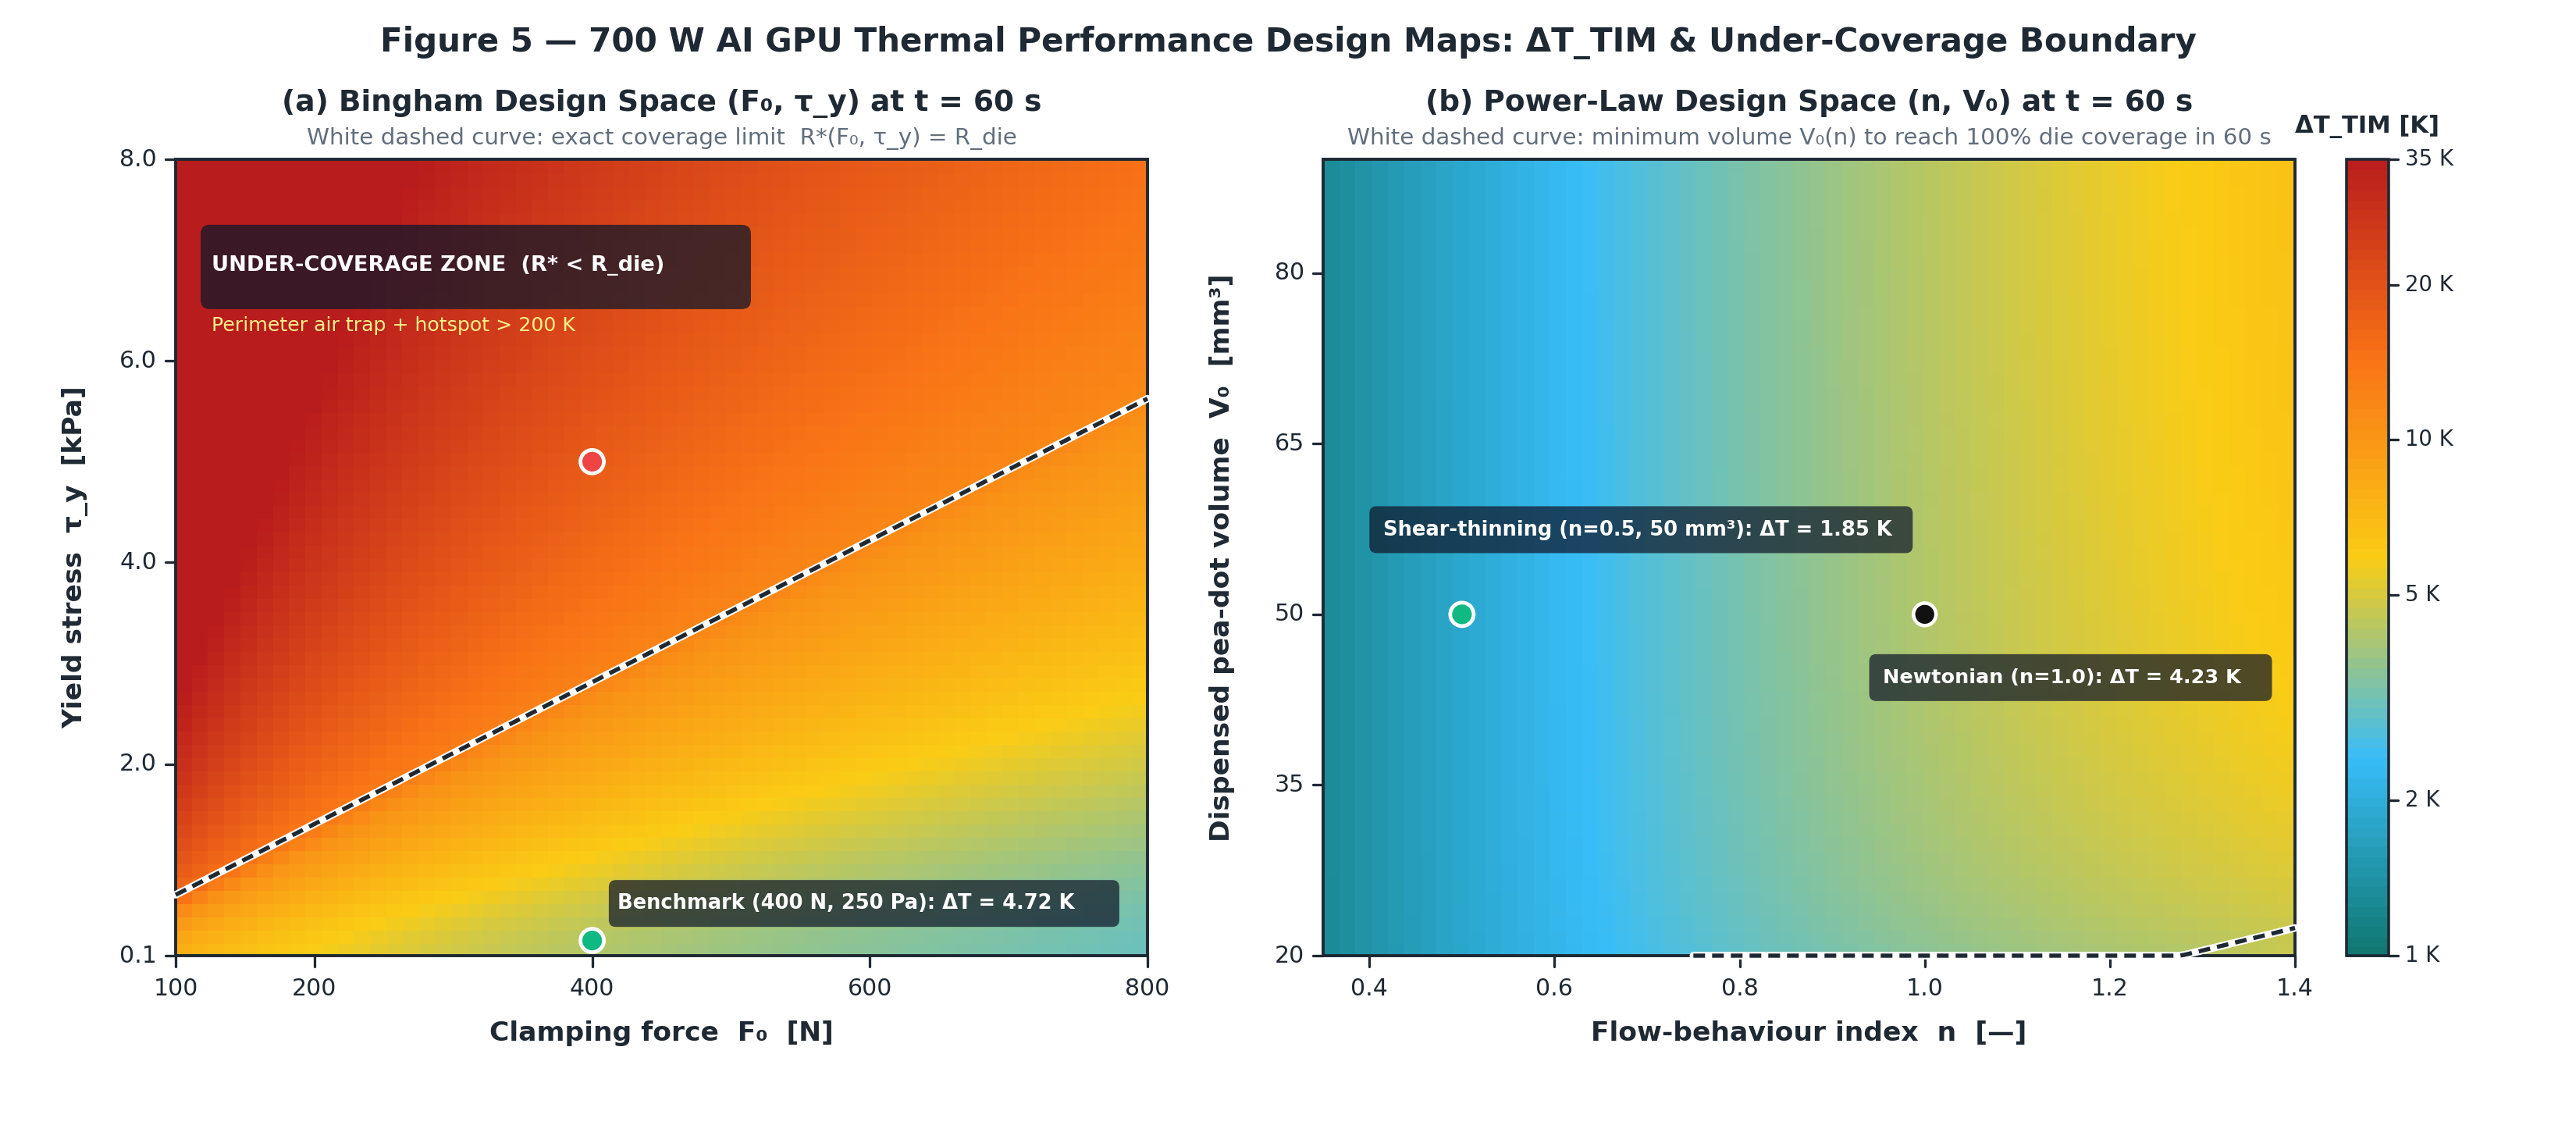

In [4]:
# Benchmark Summary Table at t = 60 s for the 700 W AI GPU across all 5 Rheological Models
t_eval = np.array([prm.MOUNT_TIME])
b_high = prm.replace(prm.BINGHAM, tau_y=5000.0, label="Bingham (tau_y=5 kPa, stall)")
models_summary = [
    ("Shear-Thinning (n=0.5, K=100)", prm.SHEAR_THINNING),
    ("Newtonian (mu=100 Pa.s)", prm.NEWTONIAN),
    ("Shear-Thickening (n=1.3, K=100)", prm.SHEAR_THICKENING),
    ("Bingham Nominal (tau_y=250 Pa)", prm.BINGHAM),
    ("Bingham High-Yield (tau_y=5 kPa)", b_high),
]

header = f"{'Rheological Model':34s} | {'h(60s) [um]':>11s} | {'R(60s) [mm]':>11s} | {'Coverage [%]':>12s} | {'R_TIM [K/W]':>11s} | {'dT_TIM [K]':>10s} | {'dT_hot [K]':>10s}"
print(header)
print("-" * len(header))
for name, fl in models_summary:
    res = rm.solve_squeeze(fl, t_eval, prm.GPU_700W.F0, prm.DROPLET.V0, prm.DROPLET.h0, prm.GPU_700W.R_die)
    th = tc.thermal_state(res.h, res.R, prm.GPU_700W, prm.THERMAL)
    print(f"{name:34s} | {res.h[0]*1e6:11.2f} | {res.R[0]*1e3:11.2f} | {th.coverage[0]*100:12.1f} | "
          f"{th.R_tim[0]:11.5f} | {th.dT_tim[0]:10.2f} | {th.dT_hotspot[0]:10.1f}")

display(Image(filename="figures/fig3_thickness_radius.png", width=880))
display(Image(filename="figures/fig5_gpu_thermal_design_map.png", width=880))


---
## 8. Buckingham $\Pi$ Dimensional Analysis, Assumption-Validity Map & 20-Check Verification Suite

Following *Dimensionless Numbers as Ratios of Physical Effects*  and the 7-Point Verification Checklist (*Conservation and Transport Equations*, Slide 83):

* **Dimensional Matrix & Buckingham $\Pi$ Count ($n - r$):**
  For constant-volume viscoplastic squeeze flow, the local state relation involves $n = 7$ variables $\{F, h, R, W, \rho, \mu_p, \tau_y\}$ spanning $r = 3$ fundamental dimensions $\{M, L, T\}$, yielding $n - r = 4$ independent dimensionless groups (plus the rheological flow index $n$ for power-law pastes):
  $$\Pi_1 = \epsilon(t) \equiv \frac{h(t)}{R(t)} \ll 1 \quad (\text{geometric lubrication ratio}), \qquad \Pi_2 = Re_{\text{sq}}(t) \equiv \frac{\rho W h}{\mu_{\text{eff}}} \ll 1 \quad (\text{inertia / viscosity})$$
  $$\Pi_3 = Bn(t) \equiv \frac{\tau_y h^2}{\mu_p R W} = \frac{3}{\Lambda} \quad (\text{yield stress / viscous stress}), \qquad \Pi_4 = \frac{F}{\mu_p W R^4 / h^3} = \frac{3\pi}{2}\frac{\Phi(\Lambda)}{\Lambda} \quad (\text{dimensionless squeeze force})$$


 #  status       error       tol  check
----------------------------------------------------------------------------------------------------
 1  PASS      4.35e-16     1e-12  Power-law (n=1, K=mu) == Newtonian  [h(t), p(r), u_r(r,z), dh/dt]
 2  PASS      6.87e-06     1e-04  Bingham (tau_y = 1e-3 Pa) -> Newtonian  [h(t), p(r), dh/dt]
 3  PASS      1.73e-09     1e-03  Bingham tau_y=250 Pa: h(t->inf) -> h* = 5.46 um (die covered, constant-area stall)
 4  PASS      0.00e+00     1e-12  Bingham tau_y=250 Pa: plastic-limit force at h* == F0
 5  PASS      0.00e+00     1e-03  Bingham tau_y=5000 Pa: h(t->inf) -> h* = 77.32 um (UNDER-COVERAGE, constant-volume stall)
 6  PASS      1.11e-15     1e-12  Bingham tau_y=5000 Pa: plastic-limit force at h* == F0
 7  PASS      6.66e-16     1e-09  Critical yield stress tau_y,crit = 3 F0 h_c / (2 pi R_die^3) = 2812.8 Pa & h*_vol(tau_y,crit) == h_c
 8  PASS      7.39e-11     1e-06  Power-law ODE vs. closed-form h(60 s) for n=0.5: 10.77 um
 9  PASS      5.43e-

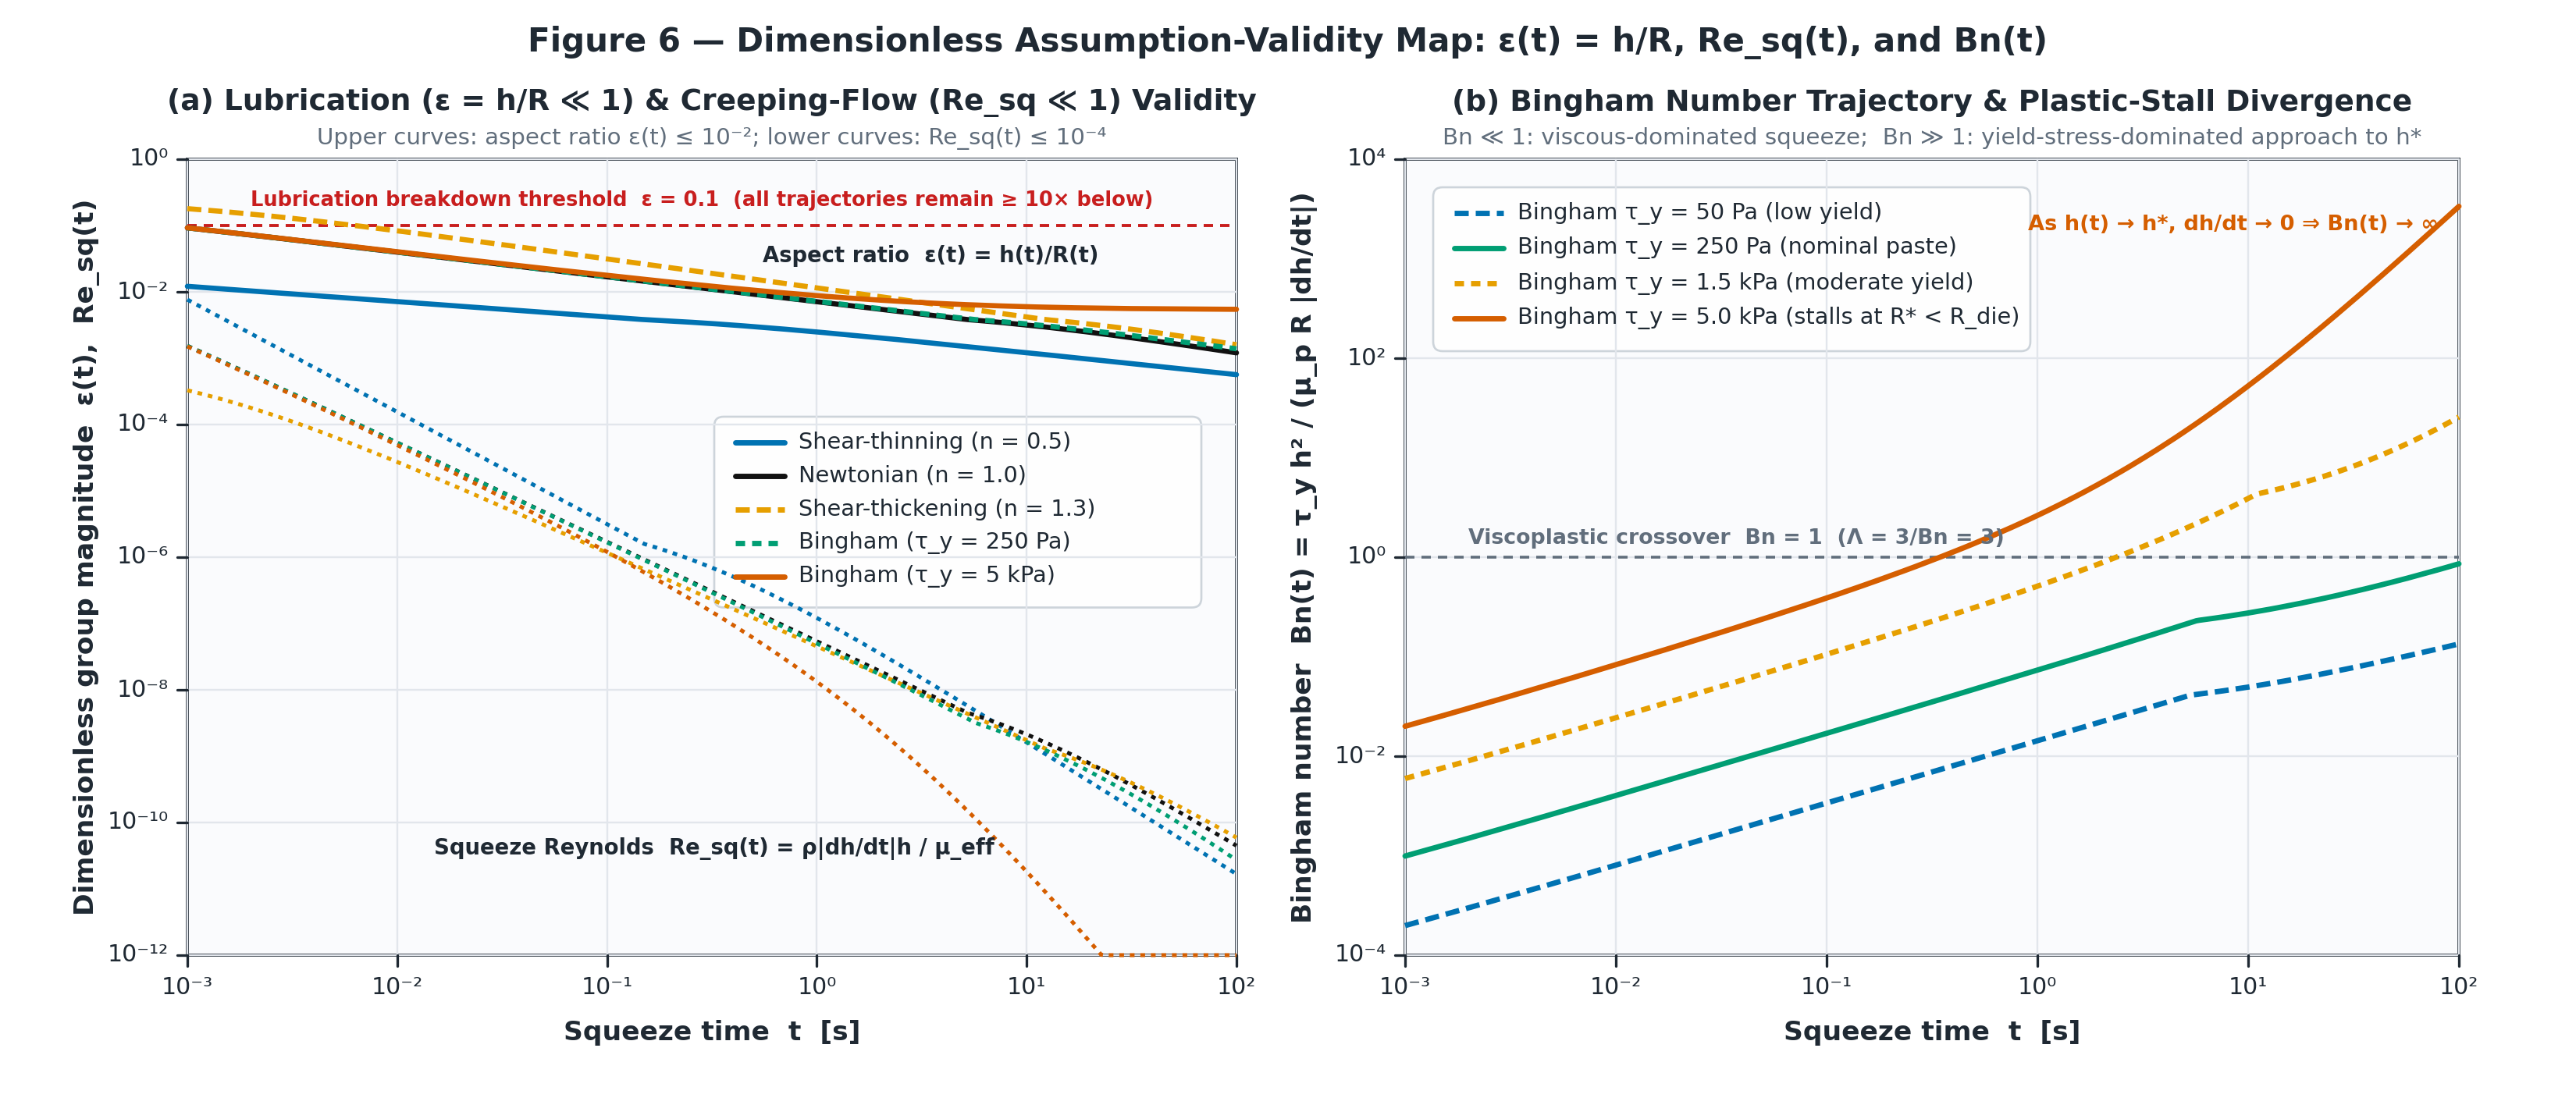

In [5]:
# Run the complete 20-check automated verification suite (limiting cases, conservation, scaling, unit invariance)
checks = dg.run_all_checks()
print(dg.format_checks(checks))
assert all(c.passed for c in checks), "One or more verification checks failed!"

display(Image(filename="figures/fig6_regime_validity.png", width=880))
